# Dalitz fit: $\eta \to \mu^+\mu^-\gamma$

The workflow is similar to the mass fit, except organized by bins in the dalitz plot:

    read ROOT -> cuts -> best candidate -> get dalitz variables
              -> global fit_gauss -> per-dalitz-bin fits -> plots

In [1]:
import sys
import os
import json

import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from iminuit.cost import NormalConstraint

# Notebooks don't define __file__; fall back to cwd.
try:
    _here = os.path.dirname(os.path.abspath(__file__))
except NameError:
    _here = os.getcwd()
for sub in ('utils', 'fit', 'plot'):
    sys.path.insert(0, os.path.join(_here, '..', sub))

import cut_utils
import kinematics
import fit_utils
import plot_utils
import plot_style
from fit_dcb import fit_dcb, TAIL_PARAMS
from plot_dcb import plot_dcb
from plot_mass_fit import build_fit_figure

In [2]:
# Configuration
INFILE = '../../ntuple/lhcb/eta2mumugamma/20260608/combined_files.root'
OUTDIR = '../../out/eta2mumugamma/turbo/20260924/'
MAX_EVENTS = None      # cap on events read, for quick iteration; None = all

# Physical constraints for the Dalitz plot [GeV^2].
M_MU  = kinematics.M_MU / 1000.0
M_ETA = kinematics.M_ETA / 1000.0


In [ ]:
M12_PHYS = (M_MU**2, (M_ETA - M_MU)**2)
M23_PHYS = ((2 * M_MU)**2, M_ETA**2)

# Branches. prt_px/py/pz/e are needed for the Dalitz variables.
# The quantity being fit is the gamma mu+ mu- mass. The phase-space factor is
# an exact identity only for a mass built from the same daughter momenta as
# the Dalitz variables, so by default it is rebuilt from prt_px/py/pz/e below.
# MASS_BRANCH is still read: as the tag-level reference branch for cut_utils,
# and as the fitted mass if REBUILD_MASS is False. Not tag_dtf_m: its
# refitted mass differs from the daughters' by ~29 MeV RMS, so the kinematic
# edges would be smeared rather than sharp. tag_m itself puts ~1% of events
# outside their own kinematic limits, i.e. where the fit model is exactly 0.
MASS_BRANCH     = 'tag_m'
REBUILD_MASS    = True
METRIC_BRANCH   = 'tag_dtf_chi2'    # ranks candidates within an event
DAUGHTER_FIELDS = ['prt_pid', 'prt_pnn_mu', 'prt_px', 'prt_py', 'prt_pz', 'prt_e']

# Every candidate is built to this composition; asserted below, not cut.
SIGNAL_DAUGHTERS = [-13, 13, 22]

# Trigger-on-signal lines per trigger level. The TOS cut requires the
# candidate to be TOS on at least one line at every level.
TOS_LINES = {
    'L0':   ['tag_l0_tos0', 'tag_l0_tos1'],       # L0DiMuon, L0Muon
    'HLT1': ['tag_hlt1_tos0', 'tag_hlt1_tos1'],   # Hlt1DiMuonNoIP, Hlt1DiMuonLowMass
    'HLT2': ['tag_hlt2_tos0', 'tag_hlt2_tos1'],   # Hlt2ExoticaPrmptDiMuonTurbo, Hlt2ExoticaDiMuonNoIPTurbo
}
BRANCHES = ([MASS_BRANCH, METRIC_BRANCH, 'prt_idx_mom'] + DAUGHTER_FIELDS
            + [line for lines in TOS_LINES.values() for line in lines])

# Selection. Set USE_TOS=False / PNN_MU_MIN=None to widen for a study.
USE_TOS    = True
PNN_MU_MIN = None

# Mass fit window. MASS_NBINS is the number of bins in the mass histogram per
# Dalitz bin.
XMIN, XMAX, MASS_NBINS = 420.0, 680.0, 80
MEAN_INIT, SIGMA_INIT = M_ETA*1000.0, 10.0

# Dalitz binning. DALITZ_NBINS is the TOTAL number of Dalitz bins, so the grid
# is sqrt(DALITZ_NBINS) per dimension.
DALITZ_NBINS = 196  # 14x14 grid
M12_RANGE = (0.0, 0.21)
M23_RANGE = (0.0, 0.31)
MIN_CANDIDATES = 10    # fewer than this in a Dalitz bin -> don't attempt a fit

# Per-bin fit prior scaling factor on mean/sigma. The larger the factor, the
# looser the prior uncertainty. The background has no per-bin prior: the
# phase-space factor does the per-bin shaping, which the global fit's
# background shape knows nothing about.
SIGNAL_PRIOR_FACTOR = 5

# Background shape for the fit. Options are 'cheb2' and 'cheb_exp'. Per bin,
# both signal and background are multiplied by the bin's phase-space factor
# (kinematics.phase_space_factor), which is what takes the shape to 0 at the
# kinematic limits.
BKG_MODEL = 'cheb2'
PHASE_SPACE = True

# Global fit's DCB tail prior: an MC tail fit (results JSON), widened by
# TAIL_PRIOR_FACTOR standard deviations (see src/fit/README.md, "Fixing tails
# from an MC fit"). On the rebuilt mass the unconstrained global fit runs its
# tail exponents off to n ~ 50-150 and fails to converge. None = no prior.
# NOTE: this MC fit was of tag_dtf_m, not the rebuilt mass -- redo it on the
# rebuilt mass for a prior that matches.
TAIL_PRIOR_PATH = '../../out/eta2mumugamma/turbo/20260903/cheb2/results_dcb_mc.json'
TAIL_PRIOR_FACTOR = 5.0

# Per-bin fit pages also written as standalone PNGs (OUTDIR/per_bin_png/),
# e.g. for src/fit/phase-space-factor.md.
FIT_PNG_BINS = [(4, 4), (6, 8), (7, 2), (1, 13), (1, 8), (12, 7)]

os.makedirs(OUTDIR, exist_ok=True)

## Read and select

Read the branches, drop events that can't be interpreted, build a
per-candidate selection mask, then reduce each event to its single best
candidate by smallest `tag_dtf_chi2`.

In [4]:
tree = cut_utils.read_branches(INFILE, BRANCHES, entry_stop=MAX_EVENTS)
tree, drop_report = cut_utils.drop_malformed(tree, tag_ref=MASS_BRANCH)

# Checks every prt_* branch against prt_idx_mom and every tag_* branch
# against tag_dtf_m, derived from the branch prefixes.
print(f"[INFO] events: read {drop_report['read']}, kept {drop_report['kept']}, "
      f"dropped {drop_report['dropped_total']}")
for reason in ('dropped_no_candidates', 'dropped_idx_out_of_range',
               'dropped_daughter_length_mismatch',
               'dropped_partial_candidate_branch'):
    if drop_report[reason]:
        print(f'[INFO]   {reason}: {drop_report[reason]}')

n_multi = int(ak.sum(ak.num(tree[MASS_BRANCH]) > 1))
print(f'[INFO] {n_multi} / {len(tree)} events have >1 candidate')

[INFO] events: read 3711492, kept 3711492, dropped 0
[INFO] 1273604 / 3711492 events have >1 candidate


In [5]:
# Check that every candidate has exactly one of each daughter.
n_cand_total = int(ak.sum(ak.num(tree[MASS_BRANCH])))
well_formed = ak.ones_like(tree[MASS_BRANCH], dtype=bool)
for pid in SIGNAL_DAUGHTERS:
    # n = Number of daughters of this PID per candidate
    n = cut_utils.reduce(tree, tree['prt_pid'] == pid, 'prt_idx_mom',
                         how='sum', target_ref=MASS_BRANCH)
    well_formed = well_formed & (n == 1)
    print(f'[INFO] pid {pid:>4}: {float(ak.mean(ak.flatten(n))):.4f} daughters '
          f'per candidate (expected exactly 1)')

n_well_formed = int(ak.sum(well_formed))
print(f'[INFO] composition: {n_well_formed} / {n_cand_total} candidates are '
      f'exactly (mu+, mu-, gamma)')
assert n_well_formed == n_cand_total, (
    f'{n_cand_total - n_well_formed} candidates are not (mu+, mu-, gamma). '
    'That is malformed input, not background -- investigate before fitting.')

[INFO] pid  -13: 1.0000 daughters per candidate (expected exactly 1)
[INFO] pid   13: 1.0000 daughters per candidate (expected exactly 1)
[INFO] pid   22: 1.0000 daughters per candidate (expected exactly 1)
[INFO] composition: 5598421 / 5598421 candidates are exactly (mu+, mu-, gamma)


In [ ]:
# Apply cuts.
keep = ak.ones_like(tree[MASS_BRANCH], dtype=bool)
tos_report = None
cutflow = [('all candidates', n_cand_total)]

# TOS on at least one line at every trigger level.
if USE_TOS:
    tos, tos_report = cut_utils.tos_mask(tree, TOS_LINES, tag_ref=MASS_BRANCH)
    keep = keep & tos
    for level, r in tos_report.items():
        cutflow.append((f'TOS up to {level}', r['candidates_tos_cumulative']))
        if r['ignored']:
            print(f"[WARN] {level} TOS lines absent in every event (contributing "
                  f"nothing): {r['ignored']}")

# ProbNNMu cut.
if PNN_MU_MIN is not None:
    # Non-muon daughters aren't subject to this cut; OR in "isn't a muon" so
    # this reduces to a plain all-reduction over the candidate.
    muon_ok = ((tree['prt_pnn_mu'] > PNN_MU_MIN)
               | (abs(tree['prt_pid']) != 13))
    keep = keep & cut_utils.reduce(tree, muon_ok, 'prt_idx_mom', how='all',
                                   target_ref=MASS_BRANCH)
    cutflow.append((f'pnn_mu > {PNN_MU_MIN}', int(ak.sum(keep))))

print('[INFO] cutflow (candidates surviving each cut, cumulative):')
for label, n in cutflow:
    print(f'[INFO]   {label:24s} {n:8d}')

In [7]:
# Reduce to one candidate per event.
# Get boolean mask of best candidate per event.
best = cut_utils.best_candidate_mask(tree, METRIC_BRANCH, keep)
# Apply `best` mask to the mass branch to get the list of masses to fit.
masses = cut_utils.values(tree, MASS_BRANCH, best)

assert int(ak.sum(best)) == len(masses)
assert ak.all(ak.sum(best, axis=1) <= 1), 'more than one best candidate in an event'
print(f'[INFO] {len(masses)} events kept a best candidate '
      f'(of {n_cand_total} candidates read)')

[INFO] 3639776 events kept a best candidate (of 5598421 candidates read)


## Dalitz variables

$m^2_{\gamma\mu^+}$ and $m^2_{\mu^+\mu^-}$ for each event's best candidate.
This is the piece with no framework equivalent: `cut_utils` reduces to a best
candidate and hands back a tag-level quantity, whereas the Dalitz plot needs
that candidate's individual daughter four-vectors.

In [8]:
GEV = 1000.0  # convert branches from MeV to GeV

# Convert from candidate to daughter level. `dmask` is True exactly for the
# daughters of the candidates `best` selected.
dmask = cut_utils.follow(tree, best, 'prt_idx_mom')
# Sanity check: should be three daughters per candidate
assert int(ak.sum(dmask)) == len(SIGNAL_DAUGHTERS) * len(masses)


def four_vector(pid_code):
    """(px, py, pz, e) in GeV for the daughter of this PID in each event's
    best candidate, aligned with `masses`."""
    match = dmask & (tree['prt_pid'] == pid_code)
    out = tuple(ak.to_numpy(ak.flatten(tree[field][match])) / GEV
                for field in ('prt_px', 'prt_py', 'prt_pz', 'prt_e'))
    assert all(len(a) == len(masses) for a in out), (
        f'pid {pid_code}: got {len(out[0])} daughters for {len(masses)} events '
        '-- the one-per-candidate guarantee does not hold')
    return out


# Compute dalitz variables from the four-vector of the daughters.
gamma, mup, mum = (four_vector(22), four_vector(-13),
                            four_vector(13))
m12s = kinematics.invariant_mass2(*gamma, *mup)      # m^2(gamma, mu+)
m23s = kinematics.invariant_mass2(*mup, *mum)   # m^2(mu+, mu-)

# gamma mu+ mu- mass from the same four-vectors [MeV], so every event obeys
# the kinematic identity the phase-space factor is built on.
if REBUILD_MASS:
    gamma_mup = tuple(a + b for a, b in zip(gamma, mup))
    m123s = kinematics.invariant_mass2(*gamma_mup, *mum)
    print(f'[INFO] {MASS_BRANCH} - rebuilt mass: median '
          f'{np.median(masses - np.sqrt(np.clip(m123s, 0, None)) * GEV):.3f} MeV')
    masses = np.sqrt(np.clip(m123s, 0, None)) * GEV

# negative m^2 cannot sit on a Dalitz plot. Masking all three arrays together
# keeps them the same length by construction.
physical = (m12s > 0) & (m23s > 0)
n_unphysical = int((~physical).sum())
m12s, m23s, masses = m12s[physical], m23s[physical], masses[physical]
print(f'[INFO] dropped {n_unphysical} events with m12^2 <= 0 or m23^2 <= 0')
print(f'[INFO] {len(masses)} events into the fit')

[INFO] tag_m - rebuilt mass: median 0.090 MeV
[INFO] dropped 0 events with m12^2 <= 0 or m23^2 <= 0
[INFO] 3639776 events into the fit


In [9]:
# Print summary statistics
print('--- Dalitz plot statistics ---')
print(f'm12 range:  [{m12s.min():.4f}, {m12s.max():.4f}]  '
      f'(physical: [{M12_PHYS[0]:.4f}, {M12_PHYS[1]:.4f}])')
print(f'm23 range:  [{m23s.min():.4f}, {m23s.max():.4f}]  '
      f'(physical: [{M23_PHYS[0]:.4f}, {M23_PHYS[1]:.4f}])')
print(f'mass range: [{masses.min():.4f}, {masses.max():.4f}]')
print(f'shapes: m12s {m12s.shape}  m23s {m23s.shape}  masses {masses.shape}')
assert m12s.shape == m23s.shape == masses.shape

--- Dalitz plot statistics ---
m12 range:  [0.0119, 0.9969]  (physical: [0.0112, 0.1955])
m23 range:  [0.0447, 1.1849]  (physical: [0.0447, 0.3002])
mass range: [398.0000, 1107.9999]
shapes: m12s (3639776,)  m23s (3639776,)  masses (3639776,)


## Raw Dalitz distributions

Create dalitz plot without any fitting. Generate plots for both the full reconstructed range and zoomed into the physical region.

In [10]:
# Functions for all future dalitz plots to share for formatting purposes.
MMU2 = M_MU**2   # [GeV^2]


def dalitz_boundary(M, n=3000):
    """Closed (m12, m23) boundary [GeV^2] of the physical Dalitz region (the
    D(M) teardrop) for a parent of mass M [MeV]. See
    anaroot/src/plot/plot_phase_space.py:dalitz_boundary."""
    M2 = (M / 1000.0)**2
    s = np.linspace(4 * MMU2, M2, n)
    beta = np.sqrt(np.clip(1 - 4 * MMU2 / s, 0, None))
    lo = MMU2 + (M2 - s) * (1 - beta) / 2
    hi = MMU2 + (M2 - s) * (1 + beta) / 2
    return np.concatenate([lo, hi[::-1]]), np.concatenate([s, s[::-1]])


def draw_dalitz_axes(ax):
    """D(m_eta) teardrop boundary and axis labels shared by every Dalitz figure."""
    bx, by = dalitz_boundary(M_ETA * 1000.0)
    ax.plot(bx, by, color='red', ls='-', lw=1, label='physical signal window')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlabel(r'$m^2_{\gamma,\mu^+}$ [GeV$^2$]')
    ax.set_ylabel(r'$m^2_{\mu^+,\mu^-}$ [GeV$^2$]')


def plot_dalitz_hist(m12s, m23s, hist_range, title, output, bins=100):
    """Raw 2D histogram of the Dalitz variables (no fitting involved)."""
    fig, ax = plt.subplots(figsize=(8, 6))
    *_, mesh = ax.hist2d(m12s, m23s, bins=bins, cmap='viridis', range=hist_range)
    fig.colorbar(mesh, ax=ax, label='Counts')
    draw_dalitz_axes(ax)
    ax.set_title(title)
    plot_style.save_plot(fig, output)


def plot_dalitz_map(values, cbar_label, title, output):
    """Per-bin quantity (e.g. a fitted yield) drawn on the Dalitz grid, with
    the (i, j) bin index -- matching per_bin_fits.pdf's page titles -- given
    on secondary top/right axes next to the physical m12/m23 axes."""
    fig, ax = plt.subplots(figsize=(7, 6))
    mesh = ax.pcolormesh(m12_edges, m23_edges, values.T, cmap='viridis',
                         shading='auto')
    fig.colorbar(mesh, ax=ax, label=cbar_label, pad=0.13)
    draw_dalitz_axes(ax)
    plot_style.add_bin_index_axes(ax, m12_edges, m23_edges)
    ax.set_title(title)
    plot_style.save_plot(fig, output)


def dalitz_font():
    """House font for the Dalitz figures; re-applied after mass-fit plots
    change font.size globally."""
    plot_utils.apply_font()
    plt.rcParams['font.size'] = 11

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260924/dalitz_raw.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260924/dalitz_raw_zoom.png.


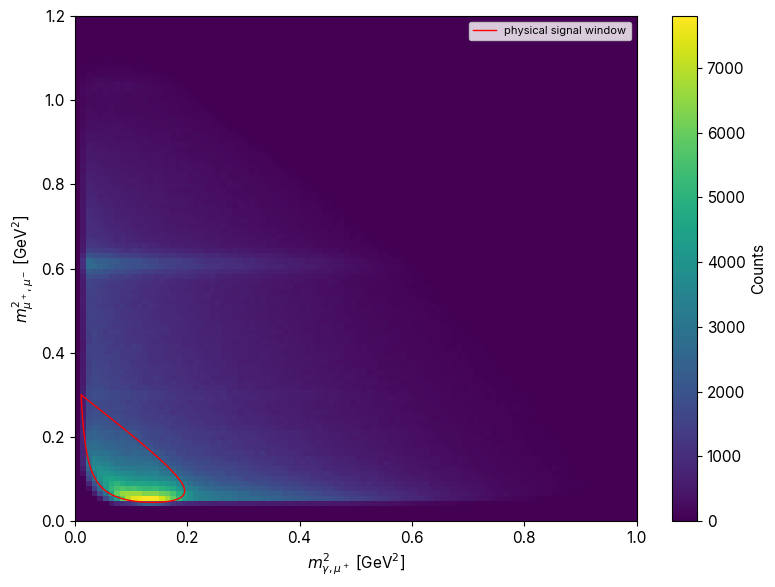

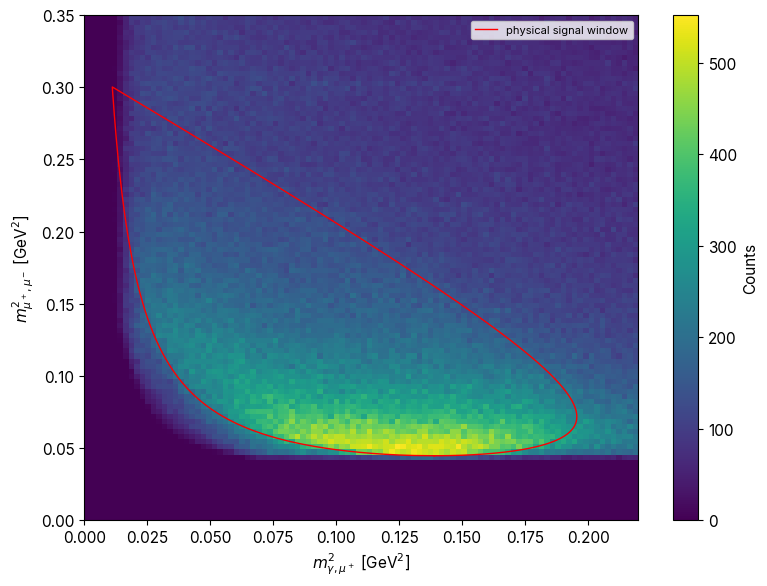

In [11]:
# Plot the raw dalitz histograms over full range and zoomed in on physical range
dalitz_font()
plot_dalitz_hist(m12s, m23s, [[0, 1.0], [0, 1.2]],
                 '', os.path.join(OUTDIR, 'dalitz_raw.png'))
plot_dalitz_hist(m12s, m23s, [[0, 0.22], [0, 0.35]],
                 '', os.path.join(OUTDIR, 'dalitz_raw_zoom.png'))

## Global mass fit

`fit_dcb()` on the whole sample, or load a previous fit from JSON.

In [ ]:
# Flag for method: do a new fit, or load a previous fit from JSON.
fit_path = None # None = do a new fit, otherwise load from this path
# A saved fit must be of the same mass variable and background model.
result, m_global = None, None
if fit_path is not None:
    with open(fit_path, 'r') as f:
        fit_result = json.load(f)
    result = fit_result
    m_global = fit_utils.LoadedFit(fit_result['fit'])
else:
    # Fit the mass distribution over all data.
    tail_prior = None
    if TAIL_PRIOR_PATH is not None:
        with open(TAIL_PRIOR_PATH, 'r') as f:
            m_mc = fit_utils.LoadedFit(json.load(f)['fit'])
        tail_prior = fit_utils.build_prior(m_mc, TAIL_PARAMS, factor=TAIL_PRIOR_FACTOR)
    result, m_global = fit_dcb(masses, xmin=XMIN, xmax=XMAX, nbins=MASS_NBINS,
                                mean_init=MEAN_INIT, sigma_init=SIGMA_INIT,
                                bkg_model=BKG_MODEL, tail_prior=tail_prior)
    result['meta']['tail_prior'] = (None if TAIL_PRIOR_PATH is None else
                                    {'path': TAIL_PRIOR_PATH, 'factor': TAIL_PRIOR_FACTOR})

    # Where the numbers came from -- the fit itself only ever saw an array.
    result['meta']['input_file'] = INFILE
    result['meta']['mass'] = 'rebuilt from daughters' if REBUILD_MASS else MASS_BRANCH
    result['meta']['selection'] = {
        'tos': USE_TOS,
        'pnn_mu_min': PNN_MU_MIN,
        'best_candidate': f'min {METRIC_BRANCH}',
        'signal_daughters': SIGNAL_DAUGHTERS,
        'composition_asserted': True,
    }
    # Selection details, so the results file is self-contained.
    result['selection_report'] = {
        'events': drop_report,
        'triggers': tos_report,
        'cutflow': [{'cut': label, 'candidates': n} for label, n in cutflow],
        'best_candidate': {
            'metric': METRIC_BRANCH, 'method': 'min',
            'events_with_best_candidate': len(masses),
        },
        'branches_read': BRANCHES,
    }

# Get global results background model (default to Chebyshev if not present)
BKG_MODEL = result['meta'].get('background_model', 'cheb2')
print(f'[INFO] global fit background model: {BKG_MODEL}')

In [13]:
# Debug: HESSE diagnostics per parameter, useful if the covariance check
# below fails.
if hasattr(m_global, 'fmin'):
    print(m_global.fmin)
    for p in m_global.parameters:
        print(f'  {p:8s} value={m_global.values[p]:12.4f}  '
              f'error={m_global.errors[p]:10.4f}  limits={m_global.limits[p]}')
else:
    print('[INFO] m_global loaded from JSON -- no HESSE diagnostics (fmin/limits)')
    for p in m_global.parameters:
        print(f'  {p:8s} value={m_global.values[p]:12.4f}  error={m_global.errors[p]:10.4f}')

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 210.9 (χ²/ndof = 2.8)      │             Nfcn = 2350              │
│ EDM = 1.43e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
  mean     value=    548.5174  error=    0.0880  limits=(-inf, inf)
  sigma    value=   

In [14]:
# Global fit's covariance for mean and sigma, loosened by SIGNAL_PRIOR_FACTOR
# (stdev multiplier), as a per-bin NormalConstraint below, preserving the
# mean-sigma correlation the global fit measured. Falls back to a diagonal
# matrix from m_global.errors if m_global.covariance is None. The background
# parameters get no prior (see SIGNAL_PRIOR_FACTOR in the config).
BKG_MODEL_OBJ = fit_utils.BACKGROUND_MODELS[BKG_MODEL]

PRIOR_PARAMS = ('mean', 'sigma')
_, cov_prior = fit_utils.build_prior(m_global, PRIOR_PARAMS, factor=SIGNAL_PRIOR_FACTOR)

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260924/global_gauss_fit.png.

────────────────────────────────────────────────
                Fit summary                 
────────────────────────────────────────────────
μ = 548.52 ± 0.09 MeV
σ = 16.44 ± 0.13 MeV
α_L = 1.41 ± 0.04, n_L = 3.4 ± 0.7
α_R = 1.05 ± 0.03, n_R = 3.43 ± 0.21
n_sig = 228894 ± 4349
n_bkg = 576506 ± 4384
c0 = 0.533 ± 0.006, c1 = 0.062 ± 0.006
χ²/ndof = 1.84
────────────────────────────────────────────────
[INFO] per-bin seeds: mean=548.517  sigma=16.436  bkg(cheb2): c0=0.533, c1=0.062
[INFO] per-bin fixed tails: alphaL=1.406  nL=3.418  alphaR=1.046  nR=3.430


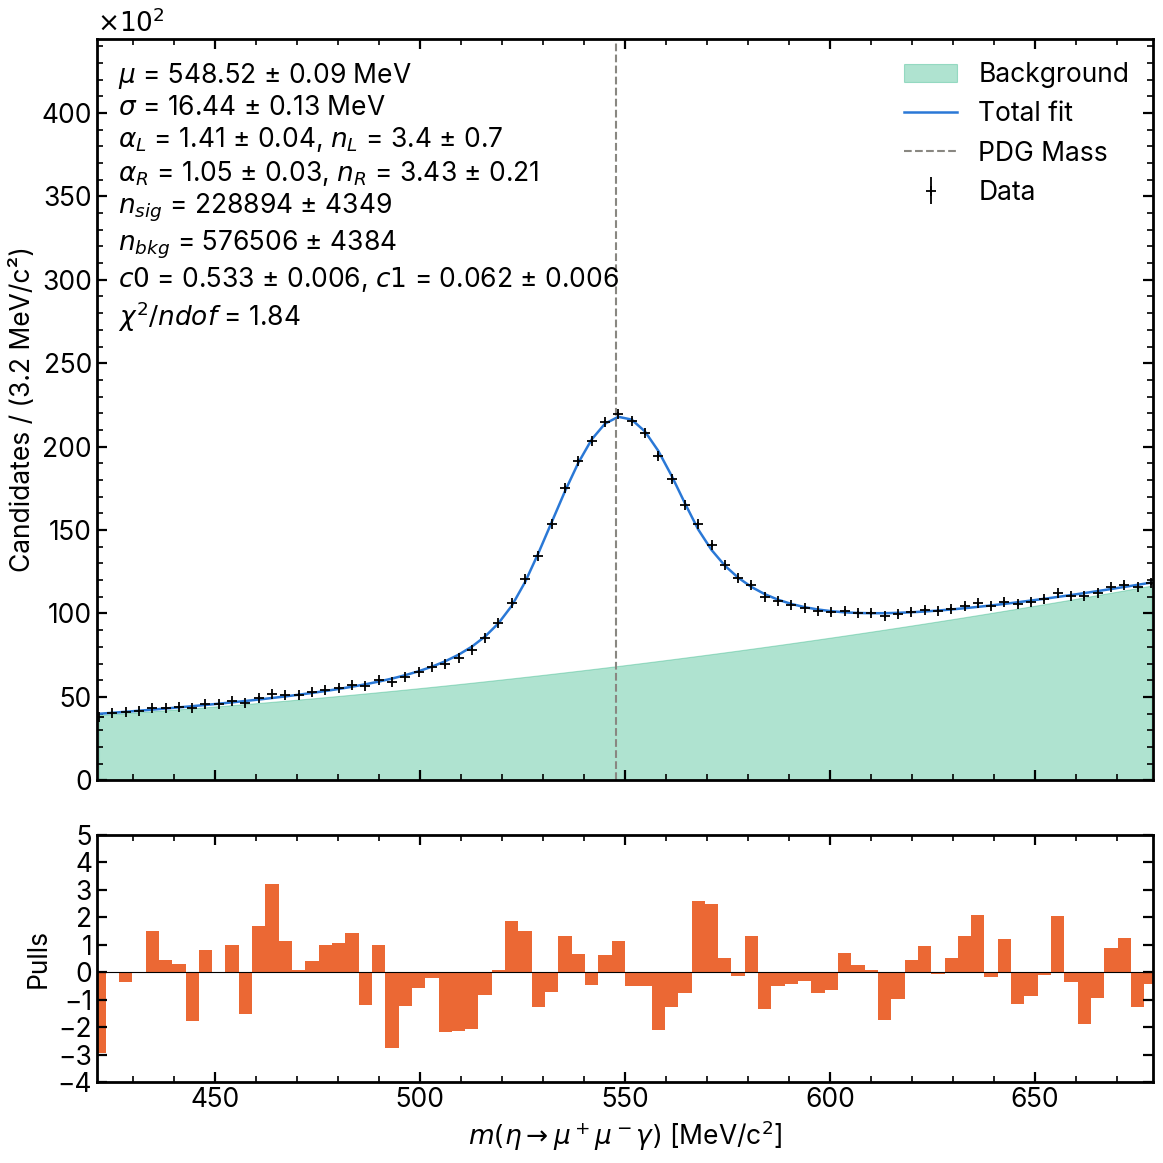

In [15]:
# Plot global fit result and store parameters for use in the per-bin fits.
plot_dcb(result, os.path.join(OUTDIR, 'global_gauss_fit.png'))

# Seed the per-bin fits from the global fit; tail shape params are held
# fixed per bin.
mean_init   = result['fit']['parameters']['mean']['value']
sigma_init  = result['fit']['parameters']['sigma']['value']
alphaL_init = result['fit']['parameters']['alphaL']['value']
nL_init     = result['fit']['parameters']['nL']['value']
alphaR_init = result['fit']['parameters']['alphaR']['value']
nR_init     = result['fit']['parameters']['nR']['value']
# Background init param names come from BKG_MODEL_OBJ.
bkg_init = {name: result['fit']['parameters'][name]['value']
            for name in BKG_MODEL_OBJ.param_names}

print(f'[INFO] per-bin seeds: mean={mean_init:.3f}  sigma={sigma_init:.3f}  '
      f'bkg({BKG_MODEL}): ' + ', '.join(f'{k}={v:.3f}' for k, v in bkg_init.items()))
print(f'[INFO] per-bin fixed tails: alphaL={alphaL_init:.3f}  nL={nL_init:.3f}  '
      f'alphaR={alphaR_init:.3f}  nR={nR_init:.3f}')

## Per-Dalitz-bin fits

Now we attempt to do the per-bin dalitz fit, but we have to be smart about it. We use the global fit results as a starting point and set custom-tuned covariance/uncertainty priors to help with convergence.

In [16]:
# Mass histogram binning, used by every per-bin fit AND every per-bin plot.
MASS_EDGES = np.linspace(XMIN, XMAX, MASS_NBINS + 1)
MASS_CENTERS = 0.5 * (MASS_EDGES[:-1] + MASS_EDGES[1:])
MASS_BIN_WIDTH = (XMAX - XMIN) / MASS_NBINS

n_per_dim = int(np.sqrt(DALITZ_NBINS))
m12_edges = np.linspace(*M12_RANGE, n_per_dim + 1)
m23_edges = np.linspace(*M23_RANGE, n_per_dim + 1)


def dalitz_bin_mask(i, j):
    """Half-open [lo, hi) mask selecting Dalitz bin (i, j)."""
    return ((m12s >= m12_edges[i]) & (m12s < m12_edges[i + 1]) &
            (m23s >= m23_edges[j]) & (m23s < m23_edges[j + 1]))


def bin_weight(i, j):
    """Phase-space factor of Dalitz bin (i, j) as fit_utils's (xg, wg), or
    None if PHASE_SPACE is off."""
    if not PHASE_SPACE: return None
    return fit_utils.make_weight(
        lambda M: kinematics.phase_space_factor(
            M, (m12_edges[i], m12_edges[i + 1]), (m23_edges[j], m23_edges[j + 1])),
        XMIN, XMAX)


def bin_shapes(weight):
    """(signal CDF, background model) for a bin, with the phase-space factor
    applied to both if `weight` is not None."""
    if weight is None:
        return fit_utils.dcb_cdf, BKG_MODEL_OBJ
    return (fit_utils.weighted_dcb_cdf(weight),
            fit_utils.weighted_bkg_model(BKG_MODEL_OBJ, weight))


def bin_prediction(fit_result, counts, weight):
    """Expected counts, data-based pulls and chi2/ndf for one bin's fit.

    `weight` is the phase-space factor the fit used (bin_weight), or None.
    """
    sig_cdf, model = bin_shapes(weight)
    p = fit_result.values
    n_sig, n_bkg = float(p['n_sig']), float(p['n_bkg'])
    bin_sig = np.diff(sig_cdf(MASS_EDGES, XMIN, XMAX, p['mean'], p['sigma'],
                              p['alphaL'], p['nL'], p['alphaR'], p['nR'])) * n_sig
    bin_bkg = np.diff(model.cdf(MASS_EDGES, XMIN, XMAX,
                                *(p[name] for name in model.param_names))) * n_bkg
    bin_fit = bin_sig + bin_bkg

    # Neyman (data-based) chi2/pulls: DATA is the variance estimate, so
    # sum(pulls**2) == chi2. Empty bins are skipped and don't count toward ndof.
    ok = counts > 0
    pulls = np.where(ok, (counts - bin_fit) / np.sqrt(np.where(ok, counts, 1.0)), 0.0)
    chi2 = float(np.sum((counts[ok] - bin_fit[ok])**2 / counts[ok]))
    ndof = int(ok.sum()) - fit_result.nfit
    return {
        'n_sig': n_sig, 'n_bkg': n_bkg,
        'bin_fit': bin_fit, 'bin_sig': bin_sig, 'bin_bkg': bin_bkg, 'pulls': pulls,
        'chi2': chi2, 'ndof': ndof,
        'chi2_per_ndof': chi2 / ndof if ndof > 0 else float('nan'),
    }

In [17]:
# Fit per Dalitz bin,
# Bins with too few candidates are skipped.
fit_results = {}
for i in range(n_per_dim):
    for j in range(n_per_dim):
        masses_in_bin = masses[dalitz_bin_mask(i, j)]
        counts, edges = np.histogram(masses_in_bin, bins=MASS_EDGES)
        counts = counts.astype(float)
        n_cand = counts.sum()
        # Count only what's inside the mass window -- that's what gets fit.
        if n_cand <= MIN_CANDIDATES: continue

        # Phase-space factor for this bin. A bin the eta itself can't reach
        # (f(m_eta) = 0: entirely outside the eta's Dalitz region) has no
        # physical signal, so n_sig is fixed to 0 there rather than letting
        # the DCB tails absorb background.
        weight = bin_weight(i, j)
        no_signal = (weight is not None
                     and np.interp(kinematics.M_ETA, *weight) == 0.0)

        cost = fit_utils.make_dcb_cost(counts, edges, XMIN, XMAX, bkg=BKG_MODEL,
                                       weight=weight)
        cost = cost + NormalConstraint(PRIOR_PARAMS, (mean_init, sigma_init),
                                       error=cov_prior)
        init = dict(mean=mean_init, sigma=sigma_init,
                    alphaL=alphaL_init, nL=nL_init,
                    alphaR=alphaR_init, nR=nR_init,
                    n_sig=0.0 if no_signal else n_cand * 0.5,
                    n_bkg=n_cand if no_signal else n_cand * 0.5,
                    # With the phase-space factor, the Chebyshev is defined
                    # over the bin's reachable range, not [XMIN, XMAX], so
                    # the global fit's coefficients don't carry over: start
                    # flat instead.
                    **(bkg_init if weight is None else BKG_MODEL_OBJ.init))
        # Only use absolutely essential limitsW
        # TODO: Try removing all limits. The priors should be enough.
        limits = dict(sigma=(0.0, None), alphaL=(0.0, None), alphaR=(0.0, None),
                      nL=(0.0, None), nR=(0.0, None),
                      n_sig=(0.0, None), n_bkg=(0.0, None),
                      **BKG_MODEL_OBJ.limits)
        # Tails fixed at the global fit's values -- too few candidates per bin
        # to float all 10 DCB params; only the core and yields move.
        # TODO: try without fixing the tails, just keep them tightly constrained
        # by the global fit's covariance (i.e., no scaling)
        fixed = ['alphaL', 'nL', 'alphaR', 'nR']
        if no_signal:
            # mean/sigma then only enter through their prior; fix them too.
            fixed += ['n_sig', 'mean', 'sigma']
        m = fit_utils.run_fit(cost, init, limits, fixed=fixed)

        fit_results[(i, j)] = {
            'fit': m,
            'n_cand': n_cand,
            'n_events': len(masses_in_bin),
            'weight': weight,
            'no_signal': no_signal,
            'm12_range': (m12_edges[i], m12_edges[i + 1]),
            'm23_range': (m23_edges[j], m23_edges[j + 1]),
        }

# Yield maps. A bin never fit, or whose fit failed, stays 0 -- the checks below
# tell those two apart. n_bkg is a free fit parameter, so read it from the fit
# rather than deriving it as n_cand - n_sig.
signal_counts = np.zeros((n_per_dim, n_per_dim))
bkg_counts = np.zeros((n_per_dim, n_per_dim))
for (i, j), r in fit_results.items():
    if not r['fit'].valid: continue
    signal_counts[i, j] = r['fit'].values['n_sig']
    bkg_counts[i, j] = r['fit'].values['n_bkg']

print(f'[INFO] fitted {len(fit_results)} / {n_per_dim**2} Dalitz bins')

[INFO] fitted 160 / 196 Dalitz bins


## Fit sanity checks

In [18]:
# A hole (yield = 0) is either too few candidates to attempt a fit, or a fit
# that ran and failed to converge.
skipped, invalid, valid = [], [], []
for i in range(n_per_dim):
    for j in range(n_per_dim):
        if (i, j) not in fit_results:              skipped.append((i, j))
        elif not fit_results[(i, j)]['fit'].valid: invalid.append((i, j))
        else:                                      valid.append((i, j))

print(f'--- Per-bin fit outcome ({n_per_dim}x{n_per_dim} = '
      f'{n_per_dim**2} Dalitz bins) ---')
print(f'  skipped (<= {MIN_CANDIDATES} raw candidates): {len(skipped)}')
print(f'  fit invalid (hole):                {len(invalid)}')
print(f'  fit valid:                         {len(valid)}')

if invalid:
    print("\n--- Raw candidate counts at 'invalid fit' holes ---")
    print('(large n_cand means the hole is a fit-convergence failure)')
    for (i, j) in invalid:
        print(f"  bin ({i:2d},{j:2d}): n_cand={fit_results[(i, j)]['n_cand']:8.0f}")

--- Per-bin fit outcome (14x14 = 196 Dalitz bins) ---
  skipped (<= 10 raw candidates): 36
  fit invalid (hole):                0
  fit valid:                         160


In [19]:
# Background positivity check: the background shape floats per bin, and a fit
# can converge (valid == True) with the background curve dipping below zero
# somewhere in [XMIN, XMAX] -- a bogus nonzero yield the holes-only check
# above misses.
# With the phase-space factor on, only the region the bin can reach (f > 0)
# matters, and the check is on the raw (unfloored) Chebyshev, in the same
# coordinates the fit used: the fit floors it at fit_utils.BKG_FLOOR, so a
# fit that relied on the floor shows up here.
x_check = np.linspace(XMIN, XMAX, 200)
neg_bkg_bins = []
for (i, j) in valid:
    r = fit_results[(i, j)]['fit']
    weight = fit_results[(i, j)]['weight']
    reachable = np.ones_like(x_check, dtype=bool) if weight is None else \
        np.interp(x_check, *weight) > 0
    model = bin_shapes(weight)[1]
    shape = model.unnorm(x_check, XMIN, XMAX,
                         *(r.values[name] for name in BKG_MODEL_OBJ.param_names))
    if np.any(shape[reachable] < 0):
        neg_bkg_bins.append((i, j))

print(f'--- Background positivity check (valid fits only, bkg_model={BKG_MODEL}) ---')
print(f'{len(neg_bkg_bins)} / {len(valid)} valid fits have a background curve '
      f'that goes negative somewhere in [XMIN, XMAX].')
for (i, j) in neg_bkg_bins[:10]:
    r = fit_results[(i, j)]['fit']
    vals = '  '.join(f'{name}={r.values[name]:.3f}' for name in BKG_MODEL_OBJ.param_names)
    print(f'  ({i:2d},{j:2d}): {vals}')

--- Background positivity check (valid fits only, bkg_model=cheb2) ---
14 / 160 valid fits have a background curve that goes negative somewhere in [XMIN, XMAX].
  ( 0, 6): c0=-1441.299  c1=-592.881
  ( 0, 8): c0=1.481  c1=0.392
  ( 0, 9): c0=1.388  c1=0.404
  ( 0,10): c0=3617.847  c1=-4636.938
  ( 0,11): c0=3.427  c1=-0.135
  ( 0,12): c0=3.505  c1=-0.724
  ( 0,13): c0=2.497  c1=-0.203
  ( 1, 7): c0=-1.300  c1=-0.871
  ( 1,10): c0=0.502  c1=-0.751
  ( 1,11): c0=1.519  c1=-1.453


In [20]:
# If a hole's raw n_cand is comparable to its immediate neighbors', the 0 in the
# yield map is a fit-convergence issue.
raw = np.full((n_per_dim, n_per_dim), np.nan)
for (i, j), r in fit_results.items():
    raw[i, j] = r['n_cand']

print('--- Neighbor comparison for holes (raw n_cand) ---')
if not invalid:
    print('No holes from non-convergence this run.')
for (i, j) in invalid:
    neighbors = {(di, dj): raw[i + di, j + dj]
                 for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]
                 if 0 <= i + di < n_per_dim and 0 <= j + dj < n_per_dim
                 and not np.isnan(raw[i + di, j + dj])}
    if neighbors:
        neighbor_str = ', '.join(f'{k}: {v:.0f}' for k, v in neighbors.items())
        print(f'  hole ({i:2d},{j:2d}): n_cand={raw[i, j]:.0f}  '
              f'neighbors: {neighbor_str}')

--- Neighbor comparison for holes (raw n_cand) ---
No holes from non-convergence this run.


In [21]:
# Per-bin yields should sum to roughly the global fit's numbers, short by the
# out-of-grid fraction.
n_sig_global = result['fit']['parameters']['n_sig']['value']
n_bkg_global = result['fit']['parameters']['n_bkg']['value']
in_grid = ((m12s >= M12_RANGE[0]) & (m12s < M12_RANGE[1]) &
           (m23s >= M23_RANGE[0]) & (m23s < M23_RANGE[1]))

print('--- Global vs summed per-bin yields ---')
print(f'  candidates in the Dalitz grid : {int(in_grid.sum())} / {len(masses)}'
      f'  ({100 * in_grid.mean():.1f}%)')
print(f'  n_sig  global {n_sig_global:10.1f}   summed {signal_counts.sum():10.1f}')
print(f'  n_bkg  global {n_bkg_global:10.1f}   summed {bkg_counts.sum():10.1f}')

--- Global vs summed per-bin yields ---
  candidates in the Dalitz grid : 1083166 / 3639776  (29.8%)
  n_sig  global   228893.9   summed   233716.2
  n_bkg  global   576506.1   summed   507901.8


## Fitted yield maps

The Dalitz plot the fits were for: signal and background yields per bin, rather
than raw candidate counts.

[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260924/dalitz_signal_yield.png.
[DONE] Plot saved to ../../out/eta2mumugamma/turbo/20260924/dalitz_bkg_yield.png.


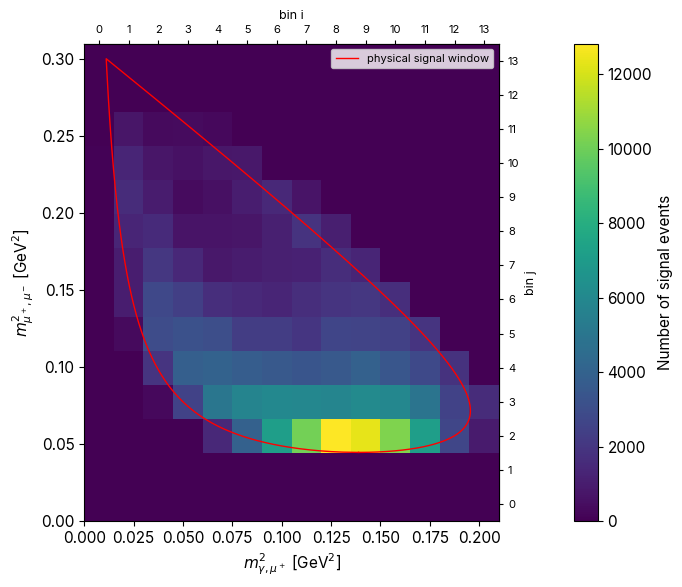

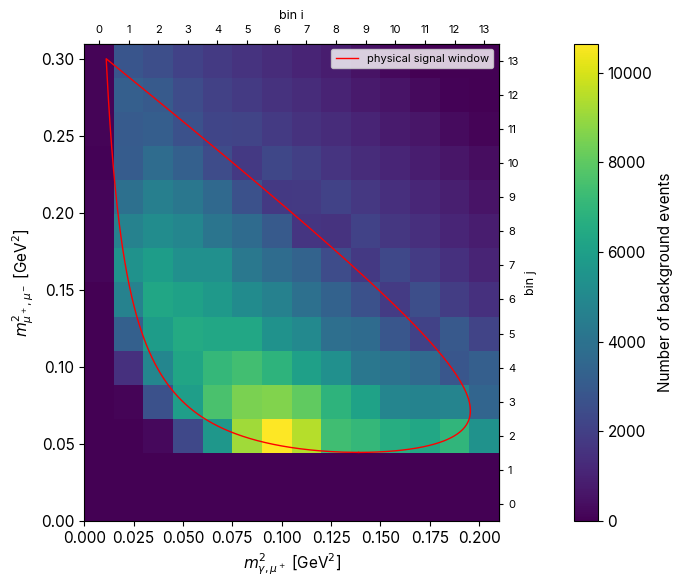

In [22]:
dalitz_font()
plot_dalitz_map(signal_counts, 'Number of signal events',
                '', os.path.join(OUTDIR, 'dalitz_signal_yield.png'))
plot_dalitz_map(bkg_counts, 'Number of background events',
                '', os.path.join(OUTDIR, 'dalitz_bkg_yield.png'))

## Results file

The global fit dict plus a `dalitz` section recording the per-bin outcome.

In [35]:
bins = []
for (i, j) in sorted(fit_results):
    r = fit_results[(i, j)]
    fit_result = r['fit']
    entry = {
        'i': i, 'j': j,
        'm12_range': [float(v) for v in r['m12_range']],
        'm23_range': [float(v) for v in r['m23_range']],
        'n_cand': float(r['n_cand']),
        'n_events': int(r['n_events']),
        'valid': bool(fit_result.valid),
        'n_sig_fixed_zero': bool(r['no_signal']),
    }
    if fit_result.valid:
        # Recount from the same mask the fit used, so chi2 here is the chi2 of
        # the histogram that was fit.
        counts, _ = np.histogram(masses[dalitz_bin_mask(i, j)], bins=MASS_EDGES)
        pred = bin_prediction(fit_result, counts.astype(float), r['weight'])
        entry.update({
            'n_sig': round(pred['n_sig'], 2),
            'n_sig_err': round(float(fit_result.errors['n_sig']), 2),
            'n_bkg': round(pred['n_bkg'], 2),
            'n_bkg_err': round(float(fit_result.errors['n_bkg']), 2),
            **{name: round(float(fit_result.values[name]), 6)
               for name in BKG_MODEL_OBJ.param_names},
            'chi2': round(pred['chi2'], 4),
            'ndof': pred['ndof'],
            'chi2_per_ndof': round(pred['chi2_per_ndof'], 6),
            'bkg_goes_negative': (i, j) in neg_bkg_bins,
        })
    bins.append(entry)

result['dalitz'] = {
    'm12_edges': m12_edges.tolist(),
    'm23_edges': m23_edges.tolist(),
    'nbins_total': DALITZ_NBINS,
    'nbins_per_dim': n_per_dim,
    'mass_window': {'xmin': XMIN, 'xmax': XMAX, 'nbins': MASS_NBINS},
    'min_candidates': MIN_CANDIDATES,
    'background_model': BKG_MODEL,
    'chi2_convention': 'neyman/data-based: sum (d - f)^2 / d',
    'pull_convention': 'data-based: (d - f) / sqrt(d)',
    'seeded_from_global_fit': list(PRIOR_PARAMS),
    'fixed_in_per_bin_fit': ['alphaL', 'nL', 'alphaR', 'nR'],
    'phase_space_factor': PHASE_SPACE,
    'phase_space_applied_to': ['signal', 'background'] if PHASE_SPACE else [],
    'mass': 'rebuilt from daughters' if REBUILD_MASS else MASS_BRANCH,
    'events_dropped_unphysical_m2': n_unphysical,
    'outcome': {'skipped': len(skipped), 'invalid': len(invalid),
                'valid': len(valid)},
    'yield_closure': {
        'n_sig_global': n_sig_global, 'n_sig_summed': float(signal_counts.sum()),
        'n_bkg_global': n_bkg_global, 'n_bkg_summed': float(bkg_counts.sum()),
        'candidates_in_grid': int(in_grid.sum()), 'candidates_total': len(masses),
    },
    'bins': bins,
}

# The fitted candidates' Dalitz variables and mass (in the grid and the mass
# window), for downstream plots that need the events themselves, e.g.
# src/plot/plot_phase_space.py --events.
in_fit = (in_grid & (masses >= XMIN) & (masses < XMAX))
np.savez_compressed(os.path.join(OUTDIR, 'dalitz_events.npz'),
                    m12s=m12s[in_fit].astype(np.float32),
                    m23s=m23s[in_fit].astype(np.float32),
                    masses=masses[in_fit].astype(np.float32),
                    m12_edges=m12_edges, m23_edges=m23_edges)

json_path = os.path.join(OUTDIR, 'dalitz_fit_results.json')
with open(json_path, 'w') as f:
    json.dump(result, f, indent=2)
print(f'[DONE] JSON saved to: {json_path}')

[DONE] JSON saved to: ../../out/eta2mumugamma/turbo/20260924/dalitz_fit_results.json


## Per-bin mass spectra

One page per Dalitz bin, including bins that were skipped or didn't converge.

In [36]:
# PdfPages opened once outside the loop; reopening per iteration would
# truncate the file to its last page.
dalitz_font()
pdf_path = os.path.join(OUTDIR, 'per_bin_fits.pdf')
n_pages = n_fitted = 0

# Stats-box text for a per-bin fit, in the same style as plot_dcb.build_text
# (mu, sigma, background params, n_sig, n_bkg, chi2/ndof) with the tail
# params omitted -- they're fixed per bin, so they'd show a meaningless
# zero error -- and n_cand folded into the extra line.
SIGNAL_KEYS = {'mean', 'sigma', 'n_sig', 'n_bkg'}

def make_build_text(n_cand):
    def build_text(params, chi2_per_ndof):
        mean, mean_err   = plot_utils.val_err(params['mean'])
        sigma, sigma_err = plot_utils.val_err(params['sigma'])
        n_sig, n_sig_err = plot_utils.val_err(params['n_sig'])
        n_bkg, n_bkg_err = plot_utils.val_err(params['n_bkg'])

        bkg_row = [(name, name, *plot_utils.val_err(params[name]), '.3f', '')
                   for name in params if name not in SIGNAL_KEYS]

        stats = [
            [(r'\mu', 'μ', mean, mean_err, '.2f', 'MeV')],
            [(r'\sigma', 'σ', sigma, sigma_err, '.2f', 'MeV')],
            [(r'n_{sig}', 'n_sig', n_sig, n_sig_err, '.0f', '')],
            [(r'n_{bkg}', 'n_bkg', n_bkg, n_bkg_err, '.0f', '')],
            bkg_row,
        ]
        extra = (
            f'$n_{{cand}}$ = {n_cand:.0f}\n$\\chi^2/ndof$ = {chi2_per_ndof:.2f}',
            f'n_cand = {n_cand:.0f}\nχ²/ndof = {chi2_per_ndof:.2f}',
        )
        return plot_style.build_stats_text(stats, extra=extra)
    return build_text


with PdfPages(pdf_path) as pdf:
    for i in range(n_per_dim):
        for j in range(n_per_dim):
            # Same mask the fit used, so the page shows the same candidates.
            mask = dalitz_bin_mask(i, j)
            counts = np.histogram(masses[mask], bins=MASS_EDGES)[0].astype(float)
            # .get() -> None for bins that were never fit at all.
            r = fit_results.get((i, j))
            fit_result = r['fit'] if r is not None else None
            has_fit = fit_result is not None and fit_result.valid

            title = (f'Bin ({i}, {j}): '
                     f'm12=[{m12_edges[i]:.4f}, {m12_edges[i + 1]:.4f}], '
                     f'm23=[{m23_edges[j]:.4f}, {m23_edges[j + 1]:.4f}]')

            if has_fit:
                p = fit_result.values
                pred = bin_prediction(fit_result, counts, r['weight'])

                params = {
                    'mean': {'value': float(p['mean']), 'error': float(fit_result.errors['mean'])},
                    'sigma': {'value': float(p['sigma']), 'error': float(fit_result.errors['sigma'])},
                    'n_sig': {'value': pred['n_sig'], 'error': float(fit_result.errors['n_sig'])},
                    'n_bkg': {'value': pred['n_bkg'], 'error': float(fit_result.errors['n_bkg'])},
                    **{name: {'value': float(p[name]), 'error': float(fit_result.errors[name])}
                       for name in BKG_MODEL_OBJ.param_names},
                }
                data = {
                    'meta': {'input_file': INFILE},
                    **({'phase_space': {'x': r['weight'][0], 'f': r['weight'][1]}}
                       if r['weight'] is not None else {}),
                    'fit': {'parameters': params, 'chi2_per_ndof': pred['chi2_per_ndof']},
                    'histogram': {
                        'bin_centers': MASS_CENTERS,
                        'bin_counts': counts,
                        'bin_errors': np.sqrt(counts),
                        'bin_fit': pred['bin_fit'],
                        'bin_sig': pred['bin_sig'],
                        'bin_bkg': pred['bin_bkg'],
                        'bin_pulls': pred['pulls'],
                    },
                }
                fig, ax, ax_pull, _, _ = build_fit_figure(
                    data, make_build_text(r['n_cand']), x_lim=(XMIN, XMAX), title=title)
                if (i, j) in FIT_PNG_BINS:
                    # Standalone copies carry no title; captions name the bin.
                    ax.set_title('')
                    png_dir = os.path.join(OUTDIR, 'per_bin_png')
                    os.makedirs(png_dir, exist_ok=True)
                    fig.tight_layout()
                    fig.savefig(os.path.join(png_dir, f'fit_{i}_{j}.png'), dpi=100)
                    ax.set_title(title)
            else:
                # No fit to draw -- data-only page, styled identically to the
                # fitted pages (font, figure size, colors, ticks/spines,
                # legend, labels) except for the fit-specific elements
                # (curves, stats box) which don't exist here.
                plot_utils.apply_font()
                plt.rcParams['font.size'] = 19
                fig, (ax, ax_pull) = plt.subplots(
                    2, 1, figsize=(12, 12), sharex=True,
                    gridspec_kw={'height_ratios': [3, 1]})
                ax.set_title(title)
                ax.set_xlim(XMIN, XMAX)
                ax.errorbar(MASS_CENTERS, counts, yerr=np.sqrt(counts), fmt='+',
                            color=plot_style.COLORS['data'], markersize=7,
                            markeredgewidth=1.3, elinewidth=1.3, capsize=0,
                            label='Data')
                ax.axvline(x=547.86, color=plot_style.COLORS['reference'],
                           linestyle='--', label='PDG Mass')
                plot_style.style_axes(ax)
                legend = ax.legend(loc='upper right', frameon=True, fancybox=False,
                                    edgecolor='none', framealpha=1)
                ax.set_ylabel(f'Candidates / ({MASS_BIN_WIDTH:.1f} MeV/c²)')

                if r is None:
                    status = (f'NO FIT ATTEMPTED\n{int(mask.sum())} candidates '
                              f'(threshold is {MIN_CANDIDATES})')
                else:
                    status = f"FIT DID NOT CONVERGE\nn_cand = {r['n_cand']:.0f}"
                status_box = ax.text(
                    0.02, 0.97, status, transform=ax.transAxes, va='top',
                    ha='left', family='monospace', color='red',
                    bbox=dict(boxstyle='round,pad=0.4', facecolor='none', edgecolor='none'))

                content_max = max(float(counts.max()) if counts.size else 0.0, 1.0)
                plot_style.reserve_top_margin(ax, content_max, artists=[status_box, legend])
                plot_style.format_y_axis(ax)

                ax_pull.text(0.5, 0.5, 'no fit', transform=ax_pull.transAxes,
                             ha='center', va='center', color='gray', fontsize=9)
                ax_pull.axhline(0, color=plot_style.COLORS['data'], lw=0.8)
                ax_pull.set_ylim(-5, 5)
                plot_style.style_axes(ax_pull, minor_y=False)
                ax_pull.set_ylabel('Pulls')
                ax_pull.set_xlabel(plot_style.decay_label({'input_file': INFILE}))

            fig.tight_layout()
            pdf.savefig(fig)
            plt.close(fig)
            n_pages += 1
            n_fitted += int(has_fit)

print(f'Wrote {n_pages} pages to {pdf_path} '
      f'({n_fitted} with a fit, {n_pages - n_fitted} data-only)')

Wrote 196 pages to ../../out/eta2mumugamma/turbo/20260924/per_bin_fits.pdf (160 with a fit, 36 data-only)
